# EGT309 Project: Exploratory Data Analysis (Week 6)
**Group name:** _<your group name>_  |  **Members:** _<member names>_

## Why we are doing this
The maintenance team looks after 50 machines and wants an early warning before something fails. Our job in the project is to predict `maintenance_required` (0 = No, 1 = Yes) from the machine readings.

Before building any model we wanted to understand the data properly: what is in it, what is wrong with it, and what actually seems to push a machine into needing maintenance. This notebook is our record of that, one step at a time. We have tried to explain our reasoning as we go, including the places where the data surprised us or where our first guess turned out to be wrong.

## The task we were given
The brief asks us, as new members of the AI Manufacturing Analytics team, to help build an alert system that tells the maintenance team when a machine is due for maintenance. The point is to stop failures from interrupting critical production runs and to keep unscheduled downtime as low as possible. The data is sensor readings from 50 machines, plus some **derived** columns. We are asked to:

1. build and evaluate at least three suitable models, and justify the choices using the dataset;
2. identify the key features that separate machines needing maintenance from those that do not, and work out which features contribute most to `maintenance_required`.

This notebook is the groundwork for both. The model building comes next (Week 7). Here we find out what the data can and cannot tell us, so that our choice of models and features rests on evidence. The feature question is answered mainly in Steps 6, 7 and 11, and the reasons for our three models are in Step 12.

## How each step is laid out
Every step uses the same four labels, so it is easy to skim:

- **Purpose**: why we are doing this step at all.
- **What we did**: the method, in plain words.
- **What we found**: the result and the conclusion we draw from it.
- **How to read the numbers / What it means for us**: what the statistics mean, and how they change what we do next.

## Roadmap

| Step | What we do | The question we are asking |
|---|---|---|
| 0 | Set up | Is everything loaded correctly? |
| 1 | Load and first look | How big is the data, and what does it cover? |
| 2 | Data quality | What is missing, wrong, duplicated or extreme? |
| 3 | Cleaning and imputation | How do we fix the problems without distorting the data? |
| 4 | Target distribution | How rare is "maintenance required"? |
| 5 | Sensor distributions | What does each sensor normally look like? |
| 6 | Sensors vs the target | Which sensors differ when maintenance is needed? |
| 7 | Thresholds | Is there a level where the risk suddenly jumps? |
| 8 | Derived columns and leakage | Which columns can we trust as inputs, and which give the answer away? |
| 9 | Correlations | Are the variables related to each other or to the target? |
| 10 | Machine and time effects | Do some machines, or some periods, behave differently? |
| 11 | Quick baseline model | How well can the raw sensors predict maintenance today? |
| 12 | Summary and plan | What did we learn, and what do we do about it? |

## A short guide to the statistics we use
We refer back to this table in the steps below.

| Statistic | How we read it |
|---|---|
| Mean vs median | If they are close, the values are fairly symmetric. If the mean is dragged away from the median, something is pulling one tail (outliers, or odd values). |
| Standard deviation | How spread out the values are. It is only meaningful next to the mean (a std of 10 on a mean of 75 is modest, a std of 29 on a mean of 43 is wide). |
| Skewness | 0 means symmetric. Large positive or negative values mean a long tail on one side. |
| Kurtosis (excess) | About 0 for a bell curve. About -1.2 for a flat, uniform spread. Large positive values mean heavy tails (lots of extremes). |
| IQR outlier fence | A value beyond Q1 - 1.5 x IQR or Q3 + 1.5 x IQR is flagged as an outlier. A flag is only a prompt to look closer, not proof of an error. |
| Correlation (r) | -1 to +1. Measures straight-line relationships only, so it can miss a "nothing happens until a cut-off" pattern. |
| Cohen's d | The gap between two group means in units of standard deviation. Rough guide: 0.2 small, 0.5 medium, 0.8 large. |
| p-value | How surprising a difference would be if there were no real effect. With 100,000 rows almost everything is "significant", so we lean on effect sizes instead. |
| ROC-AUC | 0.5 is a coin flip, 1.0 is perfect ranking. |
| PR-AUC (average precision) | Better than ROC-AUC when the positive class is rare. A useless model scores about the share of positives (here about 0.20). |
| Recall | Out of the machines that really needed maintenance, how many did we catch? This is the number the maintenance team cares about most. |

## Step 0. Set up

**Purpose.** Load the libraries and the data once, and fix the colours and constants so every chart in the notebook looks consistent.

**What we did.** We import the tools we need, look for the CSV in a few likely folders (so the notebook still runs if the project folder is rearranged), and define the sensor column names and the target. In every chart, **blue means "no maintenance needed" and red means "maintenance required"**.

We also define three small helper functions (`chance_band`, `shade_chance_band` and `label_bars`) that several steps reuse, so the chart code in each step stays short and easy to follow.

In [1]:
import warnings
warnings.filterwarnings("ignore")          # keep the output clean
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, recall_score
from sklearn.inspection import permutation_importance

# ---- Look and feel: one style for every chart ----
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.titleweight": "bold",
                     "axes.labelsize": 10, "legend.frameon": False, "axes.grid.axis": "y"})
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

BLUE, RED, GREY = "#4C78A8", "#E45756", "#7F7F7F"
TARGET_COLORS = {0: BLUE, 1: RED}          # blue = no maintenance, red = maintenance required

# ---- Column names used throughout ----
SENSORS = ["temperature", "vibration", "humidity", "pressure", "energy_consumption"]
TARGET = "maintenance_required"

# ---- Find the data file (tries a few likely folders) ----
candidates = [Path("data/proj_machine_readings.csv"),
              Path("../data/proj_machine_readings.csv"),
              Path("repo/josh_kieron_wx_project/data/proj_machine_readings.csv")]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Could not find proj_machine_readings.csv. Edit DATA_PATH to point at it.")
print("Using data file:", DATA_PATH.resolve())


# ---- Small helpers reused in several steps ----
def chance_band(rate, n):
    """Range a rate could drift from its true value by luck alone: rate +/- 2 standard errors (n readings)."""
    se = np.sqrt(rate * (1 - rate) / n)
    return rate - 2 * se, rate + 2 * se


def shade_chance_band(ax, rate, n):
    """Draw the overall rate as a line, with the 'just luck' range shaded around it (rates are shown in %)."""
    low, high = chance_band(rate, n)
    ax.axhline(rate * 100, color="black", lw=1, label=f"overall {rate * 100:.1f}%")
    ax.axhspan(low * 100, high * 100, color=BLUE, alpha=0.15, label="range expected from chance (±2 SE)")
    ax.legend(loc="upper right")


def label_bars(ax, values, fmt="{:.0f}%", pad=2):
    """Write each bar's value just above it."""
    for i, v in enumerate(values):
        ax.text(i, v + pad, fmt.format(v), ha="center", fontsize=9)

Using data file: C:\Users\joshc\Desktop\VisualStudios\Y3S2\AIAD\project\repo\josh_kieron_wx_project\data\proj_machine_readings.csv


## Step 1. Load the data and take a first look

**Purpose.** Get oriented. We need to know how many rows and columns there are, what period they cover, how often readings arrive and what type each column is. Every later number is easier to judge once we know this.

**What we did.** Load the CSV, print its shape, time range and reading interval, and check the column types.

**What each column is** (definitions and units come from the project brief):

| Column | Meaning |
|---|---|
| `timestamp` | When the reading was taken |
| `machine_id` | Which of the 50 machines (a label, not a quantity) |
| `temperature` | Machine operating temperature (°C) |
| `vibration` | Vibration level of the machine (mm/s) |
| `humidity` | Relative humidity around the machine (%) |
| `pressure` | Operating pressure (bar) |
| `energy_consumption` | Energy used during the reading interval (kWh) |
| `machine_status` | *Derived.* 0 = idle, 1 = running, 2 = failure |
| `anomaly_flag` | *Derived.* 0 = no anomaly, 1 = anomaly |
| `predicted_remaining_life` | *Derived.* Remaining useful life, in hours, before maintenance is required |
| `failure_type` | *Derived.* Normal, Vibration Issue, Overheating, Pressure Drop or Electrical Fault |
| `downtime_risk` | *Derived.* 0 to 1 (0 = no risk, 1 = very high risk) |
| `maintenance_required` | **The target we want to predict** |

The first five (the sensors) are what a machine measures about itself. The brief calls the other five *derived data*, and whether it is safe to use them as model inputs is the main question of Step 8.

In [2]:
# Read the CSV. parse_dates turns the timestamp column into real datetimes.
df = pd.read_csv(DATA_PATH, parse_dates=["timestamp"])

# Basic facts: size, time span, reading frequency and readings per machine
print("Shape (rows, columns):", df.shape)
print("Period:", df.timestamp.min(), "->", df.timestamp.max())
print("Machines:", df.machine_id.nunique())
print("Gaps between consecutive timestamps:", df.timestamp.diff().dropna().value_counts().to_dict())
readings = df.machine_id.value_counts()
print("Readings per machine: min", readings.min(), "| max", readings.max())
print()

# Column types and non-null counts (temperature has fewer non-nulls than the rest)
df.info()

Shape (rows, columns): (100000, 13)
Period: 2025-01-01 00:00:00 -> 2025-03-11 10:39:00
Machines: 50
Gaps between consecutive timestamps: {Timedelta('0 days 00:01:00'): 99999}
Readings per machine: min 1906 | max 2092

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 13 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   timestamp                 100000 non-null  datetime64[us]
 1   machine_id                100000 non-null  int64         
 2   temperature               86000 non-null   float64       
 3   vibration                 100000 non-null  float64       
 4   humidity                  100000 non-null  float64       
 5   pressure                  100000 non-null  float64       
 6   energy_consumption        100000 non-null  float64       
 7   machine_status            100000 non-null  int64         
 8   anomaly_flag              100000 non-null  int64

In [3]:
# First five rows
df.head()

,timestamp,machine_id,temperature,vibration,humidity,pressure,energy_consumption,machine_status,anomaly_flag,predicted_remaining_life,failure_type,downtime_risk,maintenance_required
0,2025-01-01 00:00:00,39,NaN,-28.65,79.96,3.73,2.16,1,0,106,Normal,0.0,0
1,2025-01-01 00:01:00,29,68.19,57.28,35.94,3.64,0.69,1,0,320,Normal,0.0,0
2,2025-01-01 00:02:00,15,98.94,50.20,72.06,1.00,2.49,1,1,19,Normal,1.0,1
3,2025-01-01 00:03:00,43,90.91,37.65,30.34,3.15,4.96,1,1,10,Normal,1.0,1
4,2025-01-01 00:04:00,8,72.32,40.69,56.71,2.68,0.63,2,0,65,Vibration Issue,0.0,1


**What we found.**
- 100,000 rows and 13 columns, covering 50 machines from 1 January to 11 March 2025 (about 10 weeks).
- There is exactly one reading per minute, and each row belongs to a single machine. That means the machines are interleaved in time, and each machine has roughly 2,000 readings.
- `temperature` has fewer non-null values than the other columns, which we follow up in Step 2.

**What it means for us.** The dataset is big enough for reliable statistics, and the regular timestamps mean we can look at trends over time later (Step 10).

### Summary statistics
Next we look at the standard summary of each numeric column. This is the quickest way to spot columns that look strange.

In [4]:
# Standard summary statistics. We leave out the ID and text columns because their mean/std mean nothing.
display(df.drop(columns=["timestamp", "machine_id", "failure_type"]).describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
temperature,86000.0,75.03,10.04,35.55,68.28,75.09,81.78,121.94
vibration,100000.0,43.32,29.13,-106.98,37.22,48.64,59.25,113.80
humidity,100000.0,55.00,14.44,30.00,42.52,54.98,67.50,80.00
pressure,100000.0,3.00,1.15,1.00,2.00,3.01,4.00,5.00
energy_consumption,100000.0,2.75,1.30,0.50,1.63,2.74,3.87,5.00
machine_status,100000.0,1.00,0.45,0.00,1.00,1.00,1.00,2.00
anomaly_flag,100000.0,0.09,0.28,0.00,0.00,0.00,0.00,1.00
predicted_remaining_life,100000.0,234.27,150.06,1.00,97.00,230.00,365.00,499.00
downtime_risk,100000.0,0.09,0.28,0.00,0.00,0.00,0.00,1.00
maintenance_required,100000.0,0.20,0.40,0.00,0.00,0.00,0.00,1.00


**How to read the numbers, and what we found.**
- **`temperature`**: mean 75.0 and median 75.1 are almost identical, with a std of 10. That points to a symmetric, bell-shaped column. Its count is 86,000 instead of 100,000, so 14,000 values are missing.
- **`vibration`**: the mean (43.3) sits well below the median (48.6), and the minimum is -107. A mean dragged below the median is a sign that something is pulling one tail down. Vibration is a magnitude, so negative values should not exist. We investigate this in Step 2.
- **`humidity`, `pressure`, `energy_consumption`**: each mean sits almost exactly in the middle of its min-max range (30 to 80 %, 1 to 5 bar, 0.5 to 5 kWh), and the std matches what a flat, uniform spread would give (range / 3.46, for example 50 / 3.46 = 14.4 for humidity). So these three look uniformly random, which we confirm in Step 5.
- **`maintenance_required`**: the mean of a 0/1 column is the share of 1s, so about **19.7%** of rows need maintenance.

**What it means for us.** Two columns need attention before modelling (`temperature` and `vibration`), and the target is not evenly split.

## Step 2. Data quality

**Purpose.** A model can only be as good as the data we give it. In this step we check for four kinds of problems: missing values, duplicates or broken timestamps, impossible values, and extreme values. We want to know what is wrong, how much, and whether it is safe to fix.

### 2.1 Missing values
**What we did.** Count the missing values in every column and plot the percentage.

,missing,pct
temperature,14000,14.0


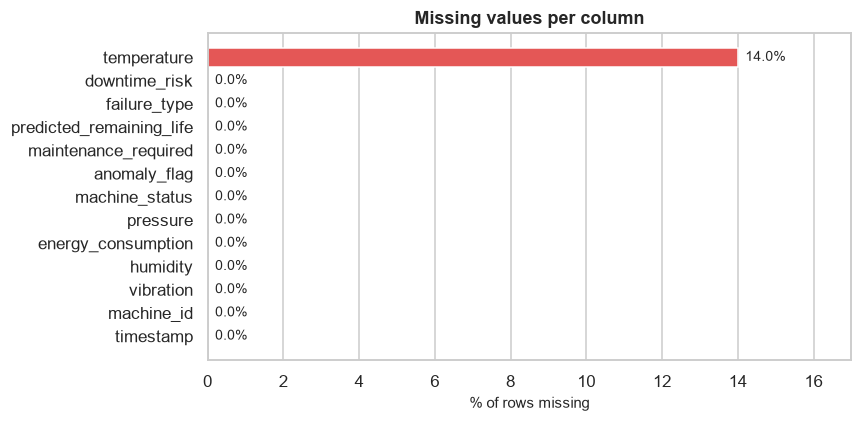

In [5]:
# Count and percentage of missing values in every column
missing = pd.DataFrame({"missing": df.isna().sum(), "pct": df.isna().mean() * 100}).round(2)
display(missing[missing.missing > 0])

# Bar chart: red = column has gaps, blue = complete
pct = missing.pct.sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(pct.index, pct, color=[RED if v > 0 else BLUE for v in pct])
for y, v in enumerate(pct):
    ax.text(v + 0.2, y, f"{v:.1f}%", va="center", fontsize=9)
ax.set(xlabel="% of rows missing", title="Missing values per column", xlim=(0, 17))
ax.grid(axis="x"); ax.grid(axis="y", visible=False)       # horizontal bars read better with vertical gridlines
plt.tight_layout(); plt.show()

**What we found.** Only `temperature` has gaps: **14,000 rows (14.0%)**. Every other column is complete.

**What it means for us.** 14% is too much to simply delete (we would throw away a lot of good information in the other columns). Whether we can safely fill the gaps depends on *why* they are missing, which is the next check.

### 2.2 Is the missing temperature random?
**Purpose.** If the gaps were not random (for example, if the sensor tended to fail exactly when a machine was about to break), then filling them in would hide a real signal, and the fact that a value is missing could itself be useful.

**What we did.** Compare the missing rate between the two target classes and across all 50 machines. For the machines, we also draw the range that pure chance would explain: with about 2,000 readings per machine, the missing rate can wander about two standard errors either side of the overall rate just by luck.

Missing rate when maintenance NOT required: 0.141 | required: 0.138
Missing rate per machine: min 0.126, max 0.157 (overall 0.140)
Chance band for one machine (overall ± 2 standard errors): 0.124 to 0.156
Machines outside that band: 2 of 50


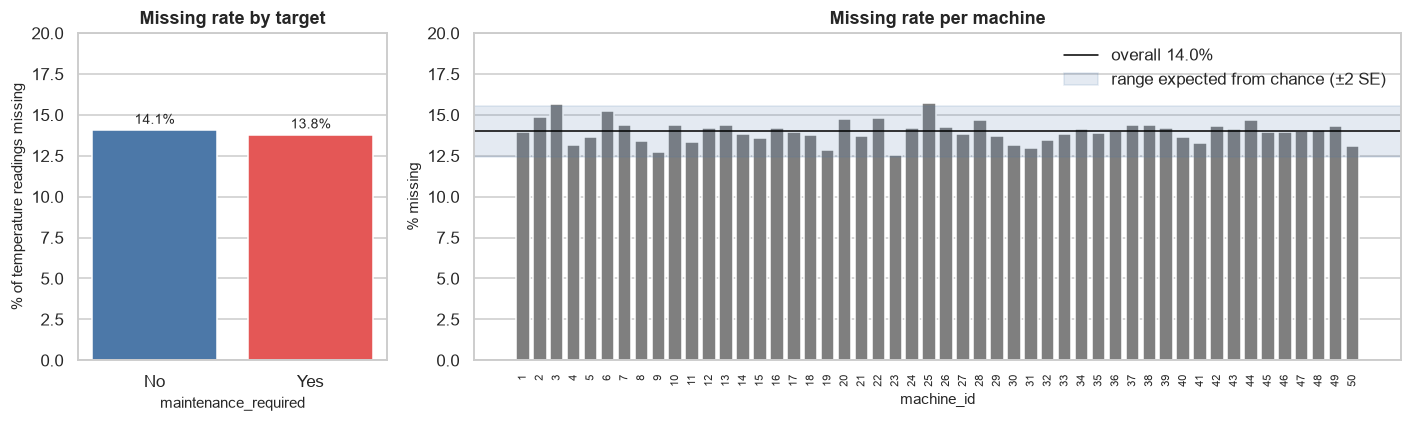

In [6]:
is_missing = df.temperature.isna()
overall = is_missing.mean()
by_target = is_missing.groupby(df[TARGET]).mean()         # missing rate for No / Yes
by_machine = is_missing.groupby(df.machine_id).mean()     # missing rate for each machine
readings_per_machine = len(df) / df.machine_id.nunique()  # about 2,000

# How far could one machine's rate drift from the overall rate by luck alone?
low, high = chance_band(overall, readings_per_machine)
n_outside = int(((by_machine < low) | (by_machine > high)).sum())

print(f"Missing rate when maintenance NOT required: {by_target[0]:.3f} | required: {by_target[1]:.3f}")
print(f"Missing rate per machine: min {by_machine.min():.3f}, max {by_machine.max():.3f} (overall {overall:.3f})")
print(f"Chance band for one machine (overall ± 2 standard errors): {low:.3f} to {high:.3f}")
print(f"Machines outside that band: {n_outside} of 50")

fig, ax = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1, 3]})

# Left: missing rate for each target class
ax[0].bar(["No", "Yes"], by_target * 100, color=[BLUE, RED])
label_bars(ax[0], by_target * 100, fmt="{:.1f}%", pad=0.4)
ax[0].set(ylim=(0, 20), ylabel="% of temperature readings missing", xlabel="maintenance_required",
          title="Missing rate by target")

# Right: missing rate for each machine, against the 'just luck' band
ax[1].bar(by_machine.index.astype(str), by_machine * 100, color=GREY)
shade_chance_band(ax[1], overall, readings_per_machine)
ax[1].set(ylim=(0, 20), xlabel="machine_id", ylabel="% missing", title="Missing rate per machine")
ax[1].tick_params(axis="x", labelrotation=90, labelsize=7)
plt.tight_layout(); plt.show()

**What we found.**
- The missing rate is about 14% whether or not maintenance is required, so the gaps do not point to either class.
- Across machines it ranges from about 12.6% to 15.7%. Only 2 of the 50 machines fall outside the shaded band, which is about what chance alone would give: with 50 machines and a band that covers roughly 95% of luck, one or two stragglers are expected.

**How to read it.** The shaded band is the "just bad luck" zone. Bars inside it tell us nothing unusual is happening. We saw no machine or class that stands out.

**What it means for us.** The data looks *missing completely at random* (MCAR), at least as far as the variables we can check. That makes it reasonable to fill the gaps. We should be honest about the limit here: we can only test against the columns we have, so we cannot fully rule out a hidden cause. As a safety net we will keep a `temperature_missing` flag, so a model can still use the information if it turns out to matter.

### 2.3 Duplicates, timestamps and value ranges
**Purpose.** Check the basics: repeated rows would give some readings extra weight, and sensor values outside a believable range would point to errors.

**What we did.** Count duplicate rows, check that each timestamp appears once, and list the min and max of every sensor.

In [7]:
# Duplicates and ordering
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate timestamps:", df.timestamp.duplicated().sum(), "| timestamps in order:", df.timestamp.is_monotonic_increasing)
print()

# Min / max of every sensor, plus how many negative values each has
display(df[SENSORS].agg(["min", "max"]).T.assign(negative_values=(df[SENSORS] < 0).sum()))

Duplicate rows: 0
Duplicate timestamps: 0 | timestamps in order: True



,min,max,negative_values
temperature,35.55,121.94,0
vibration,-106.98,113.80,6703
humidity,30.00,80.00,0
pressure,1.00,5.00,0
energy_consumption,0.50,5.00,0


**What we found.** There are no duplicate rows and no duplicate timestamps, and the readings are in strict time order. Humidity (30 to 80), pressure (1 to 5) and energy (0.5 to 5) stay inside sensible ranges. The only sensor with negative numbers is `vibration` (6,703 of them), and `temperature` reaches 121.9 °C at the top end.

**What it means for us.** Nothing needs removing here. The two sensors that need a closer look are vibration (negatives) and temperature and vibration (extreme highs, in 2.5).

### 2.4 Negative vibration
**Purpose.** Vibration in mm/s is a size, so a negative value should be impossible. Before deciding what to do with these 6.7% of rows, we need to know if the sign carries any meaning.

**What we did.** Compare the maintenance rate of negative and non-negative rows, and plot the vibration histogram before and after taking the absolute value.

Rows with negative vibration: 6703 (6.7%)
Maintenance rate | negative: 0.196 | non-negative: 0.197
Median of positive values: 50.0 | median of |negative values|: 50.0


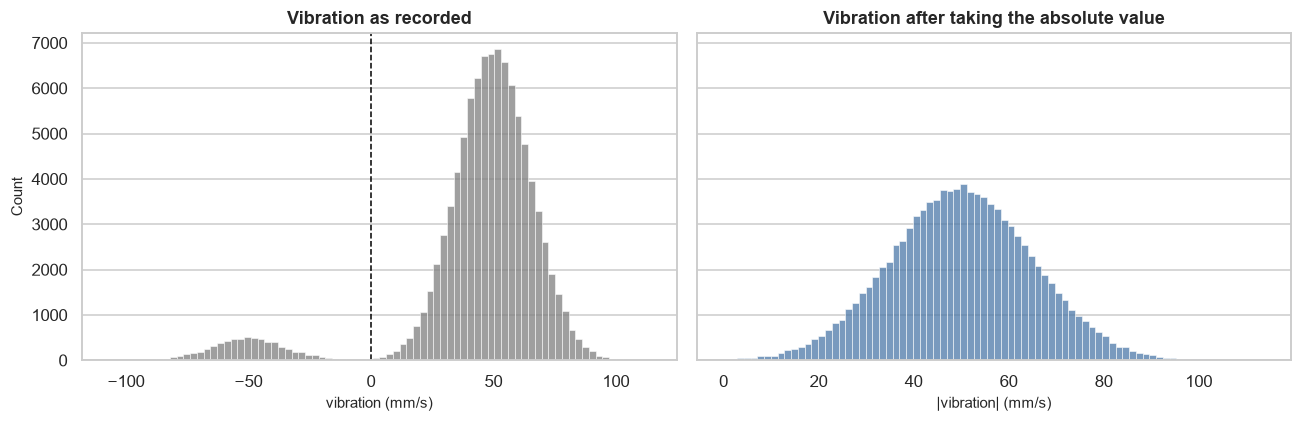

In [8]:
neg = df.vibration < 0
print(f"Rows with negative vibration: {neg.sum()} ({neg.mean() * 100:.1f}%)")

# Does the sign say anything about the target?
print(f"Maintenance rate | negative: {df[neg][TARGET].mean():.3f} | non-negative: {df[~neg][TARGET].mean():.3f}")

# If the negatives are just sign flips, their typical SIZE should match the positive values
print(f"Median of positive values: {df.vibration[~neg].median():.1f} | median of |negative values|: {df.vibration[neg].abs().median():.1f}")

# Before and after taking the absolute value
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
sns.histplot(df.vibration, bins=80, ax=ax[0], color=GREY)
ax[0].axvline(0, color="black", ls="--", lw=1)
ax[0].set(title="Vibration as recorded", xlabel="vibration (mm/s)")
sns.histplot(df.vibration.abs(), bins=80, ax=ax[1], color=BLUE)
ax[1].set(title="Vibration after taking the absolute value", xlabel="|vibration| (mm/s)")
plt.tight_layout(); plt.show()

**What we found.**
- The maintenance rate is almost the same for negative and non-negative rows, so the sign tells us nothing about the target.
- The negative values are a smaller, mirrored copy of the positive ones: the median size is about the same on both sides. The left chart shows a small "ghost" hump on the negative side, and the right chart shows that taking the absolute value folds it neatly back into one bell shape.

**How to read it.** This is why the mean was lower than the median back in Step 1: about 7% of values had their sign flipped, which pulled the mean down.

**What it means for us.** The negatives look like a sign error rather than a different kind of reading, so the sensible fix is `abs(vibration)`. We will also keep a `vibration_was_negative` flag so we do not lose the information that a flip happened.

### 2.5 Outliers
**Purpose.** Extreme values can be sensor glitches (which we would remove) or genuine events (which we must keep, because they may be exactly what we want to predict). We need to know which this is.

**What we did.** Apply the IQR fence rule to each sensor (using |vibration|) and, importantly, check what the maintenance rate is among the flagged rows.

,lower fence,upper fence,high outliers,low outliers,% of rows,maintenance rate (high outliers),maintenance rate (low outliers)
sensor,,,,,,,
temperature,48.0,102.0,298,351,0.75,1.0,0.151
|vibration|,9.8,90.3,350,364,0.71,1.0,0.179
humidity,5.1,105.0,0,0,0.00,NaN,NaN
pressure,-1.0,7.0,0,0,0.00,NaN,NaN
energy_consumption,-1.7,7.2,0,0,0.00,NaN,NaN


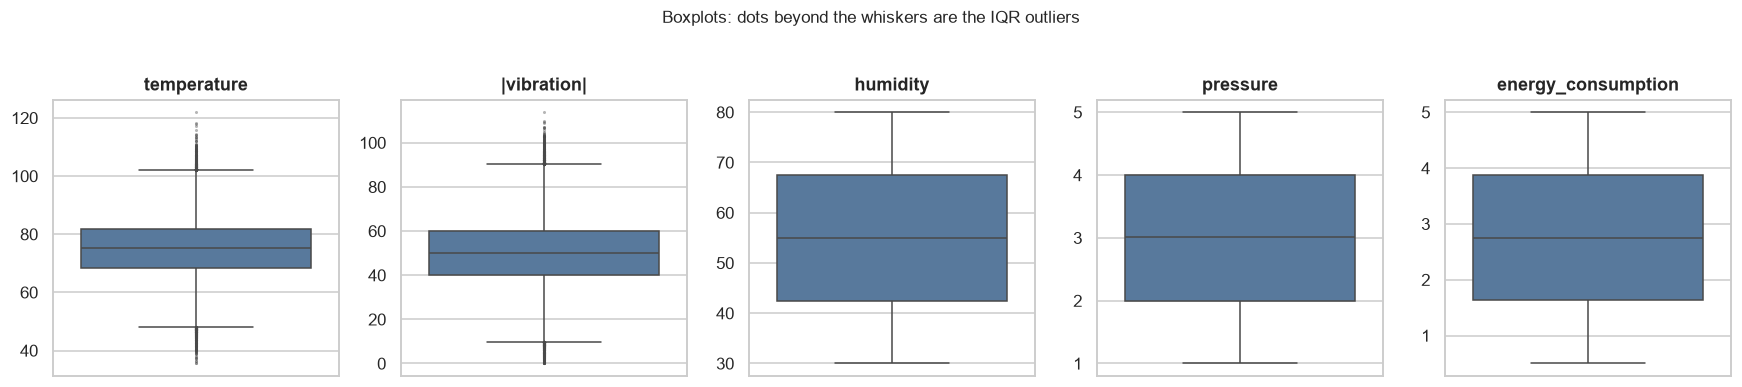

In [9]:
def iqr_summary(name, s):
    """Flag values beyond the IQR fences and report how often those rows need maintenance."""
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low_fence, high_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    high, low = s > high_fence, s < low_fence
    maint_rate = lambda mask: df.loc[s.index[mask], TARGET].mean() if mask.any() else np.nan
    return {"sensor": name, "lower fence": low_fence, "upper fence": high_fence,
            "high outliers": int(high.sum()), "low outliers": int(low.sum()),
            "% of rows": (high | low).mean() * 100,
            "maintenance rate (high outliers)": maint_rate(high),
            "maintenance rate (low outliers)": maint_rate(low)}

# For vibration we use the absolute value (see 2.4)
series = {"temperature": df.temperature, "|vibration|": df.vibration.abs(), "humidity": df.humidity,
          "pressure": df.pressure, "energy_consumption": df.energy_consumption}
table = pd.DataFrame([iqr_summary(name, s) for name, s in series.items()]).set_index("sensor")
display(table.round({"lower fence": 1, "upper fence": 1, "% of rows": 2,
                     "maintenance rate (high outliers)": 3, "maintenance rate (low outliers)": 3}))

# One boxplot per sensor: dots beyond the whiskers are the outliers
fig, axes = plt.subplots(1, 5, figsize=(16, 3.4))
for ax, (name, s) in zip(axes, series.items()):
    sns.boxplot(y=s, ax=ax, color=BLUE, flierprops={"marker": ".", "markersize": 2, "alpha": 0.4})
    ax.set(title=name, ylabel="")
plt.suptitle("Boxplots: dots beyond the whiskers are the IQR outliers", y=1.03, fontsize=11)
plt.tight_layout(); plt.show()

**What we found.**
- Humidity, pressure and energy have no outliers at all (they are uniform and bounded).
- `temperature` has about 650 outliers and `|vibration|` about 710, each under 1% of the rows. We split them into the high end and the low end, and the two ends behave completely differently.
- **Every high outlier** (298 temperature rows above about 102 °C and 350 vibration rows above about 90 mm/s) has `maintenance_required = 1`, a maintenance rate of 1.0.
- The **low outliers** are ordinary. Their maintenance rate (15% for temperature, 18% for vibration) is close to what we see everywhere else.

**How to read it.** If the high outliers were random sensor glitches, they would show up at the normal 20% maintenance rate, just like the low ones. Instead all of them sit in the "maintenance needed" group. That is far too consistent to be noise. The mixed rate in the table (54% and 58%) is just the high and low ends averaged together.

**What it means for us.** The high extremes are real events, and they are the strongest early clue about what triggers maintenance. We will **not** remove outliers. Deleting them would remove exactly the cases our model needs to learn from.

## Step 3. Cleaning and imputation

**Purpose.** Apply the decisions from Step 2 so that we have a usable version of the data. We do the work on a copy (`df_clean`) so the raw data stays untouched and we can always compare against it.

**What we did.**
- **Temperature (14% missing, looks random).** Fill each gap with the **median temperature of the same machine**. The median is robust to outliers, and using the machine's own median respects any machine-level differences. We also add a `temperature_missing` flag.
- **Vibration (6.7% negative).** Replace with `abs(vibration)` and add a `vibration_was_negative` flag.
- We **keep all outliers** (see 2.5) and keep all 100,000 rows.

Missing sensor values after cleaning: 0
Negative vibration after cleaning: 0
Rows kept: 100000 of 100000


,raw (non-missing only),after imputation
count,86000.00,100000.00
mean,75.03,75.04
std,10.04,9.31
min,35.55,35.55
25%,68.28,69.50
50%,75.09,75.08
75%,81.78,80.58
max,121.94,121.94


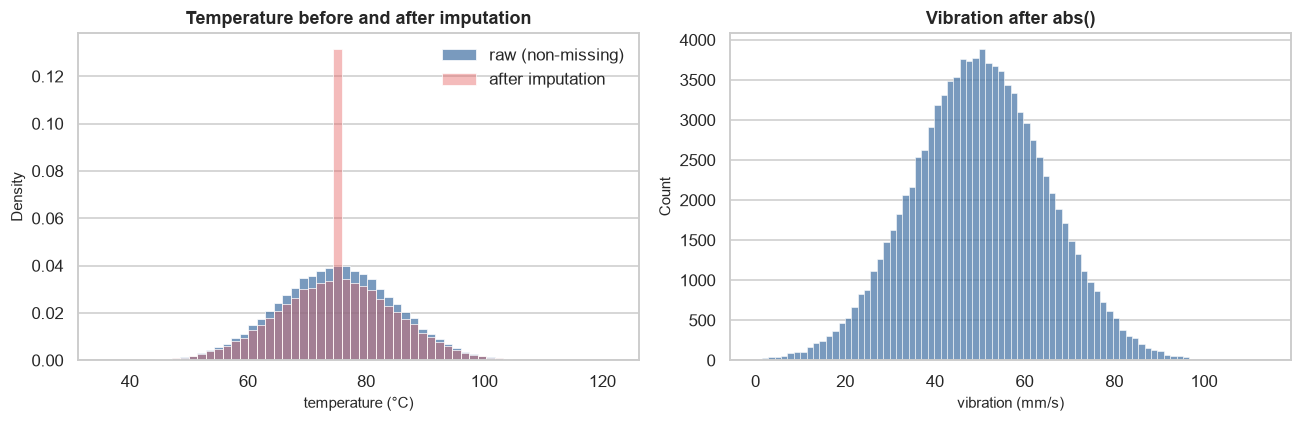

In [10]:
df_clean = df.copy()      # work on a copy so the raw data stays untouched

# --- Temperature: flag the gaps, then fill each with that machine's median ---
df_clean["temperature_missing"] = df_clean.temperature.isna().astype(int)
machine_median = df_clean.groupby("machine_id").temperature.transform("median")
df_clean["temperature"] = df_clean.temperature.fillna(machine_median)
df_clean["temperature"] = df_clean.temperature.fillna(df_clean.temperature.median())   # safety net if a machine had no readings

# --- Vibration: flag the negatives, then take the absolute value ---
df_clean["vibration_was_negative"] = (df_clean.vibration < 0).astype(int)
df_clean["vibration"] = df_clean.vibration.abs()

# --- Check the result ---
print("Missing sensor values after cleaning:", int(df_clean[SENSORS].isna().sum().sum()))
print("Negative vibration after cleaning:", int((df_clean.vibration < 0).sum()))
print("Rows kept:", len(df_clean), "of", len(df))

# Did filling the gaps change the shape of the temperature distribution?
display(pd.DataFrame({"raw (non-missing only)": df.temperature.describe(),
                      "after imputation": df_clean.temperature.describe()}).round(2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df.temperature.dropna(), bins=60, stat="density", ax=ax[0], color=BLUE, label="raw (non-missing)")
sns.histplot(df_clean.temperature, bins=60, stat="density", ax=ax[0], color=RED, alpha=0.4, label="after imputation")
ax[0].set(title="Temperature before and after imputation", xlabel="temperature (°C)"); ax[0].legend()
sns.histplot(df_clean.vibration, bins=80, ax=ax[1], color=BLUE)
ax[1].set(title="Vibration after abs()", xlabel="vibration (mm/s)")
plt.tight_layout(); plt.show()

**What we found.** No missing sensor values and no negative vibration remain, and we still have all 100,000 rows. The mean temperature is unchanged (75.0 °C) and the median barely moves.

**How to read it.** The standard deviation shrinks a little (about 10.0 to 9.3) and the red histogram has a taller peak in the middle. That is the usual cost of filling gaps with a typical value: the filled rows all land near the centre, so the data looks slightly less spread out than it really is. We think this is an acceptable trade-off, but it is worth remembering when we look at the temperature results.

**What it means for us.**
- The cleaned data is ready for modelling, and the two flags keep the "this was fixed" information available.
- For the modelling stage, the medians should be **calculated on the training split only**, then applied to the test split. If we calculate them on all the data, a little information from the test set leaks into training. We do it on the full data here only because this is exploration.
- Some of our later analysis uses the raw temperature (with the gaps left in) so that filled-in values do not blur the picture. We say so when we do.

## Step 4. Target distribution

**Purpose.** Before looking at what predicts maintenance, we need to know how common maintenance is. This decides how we should measure a model and whether we need special handling.

**What we did.** Count and plot the two classes, and work out what a model that never predicts maintenance would score.

                       rows  percent
maintenance_required                
0                     80303     80.3
1                     19697     19.7

Accuracy of a model that always answers 'No': 80.3%


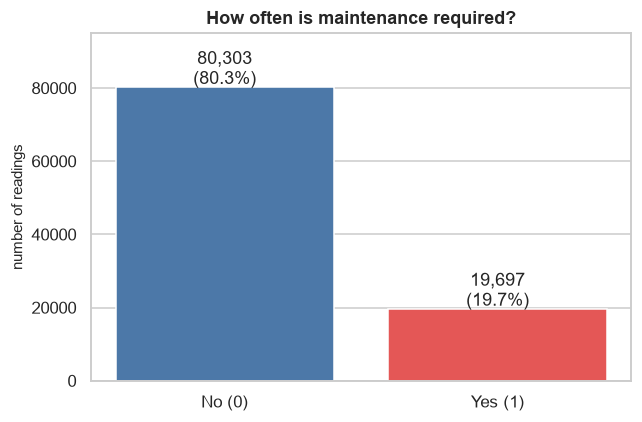

In [11]:
counts = df[TARGET].value_counts().sort_index()      # rows in each class
share = counts / len(df) * 100                       # as a percentage
print(pd.DataFrame({"rows": counts, "percent": share.round(1)}))
print(f"\nAccuracy of a model that always answers 'No': {share[0]:.1f}%")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["No (0)", "Yes (1)"], counts, color=[BLUE, RED])
for i, (n, p) in enumerate(zip(counts, share)):
    ax.text(i, n + 800, f"{n:,}\n({p:.1f}%)", ha="center")
ax.set(ylim=(0, 95000), ylabel="number of readings", title="How often is maintenance required?")
plt.tight_layout(); plt.show()

**What we found.** The target is imbalanced: about **80% "No" and 20% "Yes"** (80,303 vs 19,697 rows).

**How to read it.** A lazy model that always says "No" would be 80.3% accurate while catching **zero** machines that need maintenance. So accuracy is a misleading score for this problem.

**What it means for us.**
- We will judge models mainly on **recall, F1 and PR-AUC for the "Yes" class**. A missed maintenance (false negative) means an unplanned breakdown, which is the costly mistake.
- We will use **stratified** train/test splits so both sets keep the 80/20 balance, and we may use class weights.

## Step 5. Sensor distributions

**Purpose.** Learn what "normal" looks like for each sensor on its own, ignoring the target for now. The shape of a distribution tells us what kind of process produced it and which models and transformations make sense.

**What we did.** Draw a histogram with a smoothed curve for each sensor, mark the mean, and compute skewness and kurtosis. We use the cleaned vibration (absolute value) and the raw temperature without the filled-in values.

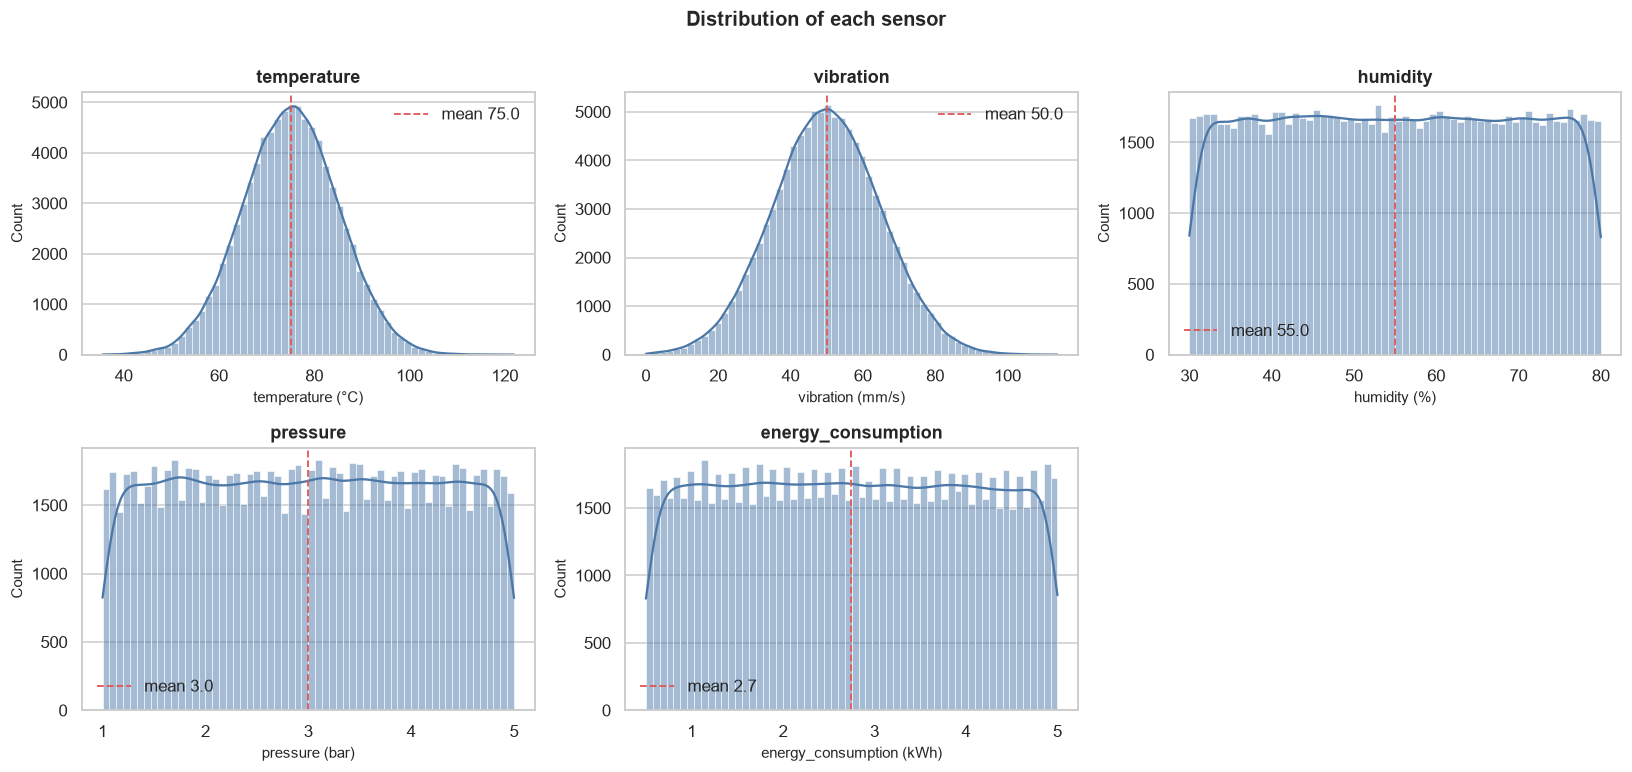

,mean,median,std,skew,excess kurtosis
temperature,75.03,75.09,10.04,-0.01,0.02
vibration,50.02,49.96,14.97,0.01,-0.02
humidity,55.00,54.98,14.44,0.00,-1.20
pressure,3.00,3.01,1.15,-0.00,-1.20
energy_consumption,2.75,2.74,1.30,0.01,-1.20


In [12]:
# "Analysis frame" used from here on: temperature keeps its gaps (so filled-in values don't blur
# the patterns) and vibration is the absolute value.
an = df.copy()
an["vibration"] = an.vibration.abs()
units = {"temperature": "°C", "vibration": "mm/s", "humidity": "%", "pressure": "bar", "energy_consumption": "kWh"}

# Histogram plus smooth curve for each sensor, with the mean marked
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), SENSORS):
    values = an[c].dropna()
    sns.histplot(values, bins=60, kde=True, ax=ax, color=BLUE)
    ax.axvline(values.mean(), color=RED, ls="--", lw=1.2, label=f"mean {values.mean():.1f}")
    ax.set(title=c, xlabel=f"{c} ({units[c]})"); ax.legend()
axes.ravel()[-1].axis("off")                        # sixth panel is unused
plt.suptitle("Distribution of each sensor", y=1.0, fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

# The numbers behind the shapes
summary = an[SENSORS].agg(["mean", "median", "std", "skew", "kurt"]).T.rename(columns={"kurt": "excess kurtosis"})
display(summary.round(2))

**What we found.**
- **`temperature` and `vibration`** are bell-shaped. Their skewness is about 0 and excess kurtosis about 0, which is what a normal distribution gives, and the mean and median match.
- **`humidity`, `pressure` and `energy_consumption`** are flat. Their excess kurtosis is about **-1.2**, which is the textbook value for a uniform distribution, and the histograms show no peak at all.

**How to read it.** A uniform sensor means "any value in the range is equally likely", which is typical of a randomly generated or very noisy signal. A bell-shaped sensor behaves like a real measurement that clusters around a typical level.

**What it means for us.**
- Skewness is near zero everywhere, so no log or power transform is needed to fix skew.
- Because the three uniform sensors have no structure of their own, we expect them to be weak predictors unless the target depends on them in a more subtle way (we test this in Steps 6 and 11).
- Tree-based models do not need the sensors to be scaled. Logistic regression will, so we will standardise inside the pipeline.

## Step 6. How each sensor relates to the target

**Purpose.** Find out which sensors look different when maintenance is required. These are the candidates for the strongest predictors.

**What we did.** Overlay the distribution of each sensor for the two classes (blue = no maintenance, red = maintenance), then put numbers on the gap: the difference in means, Cohen's d, and a Mann-Whitney test.

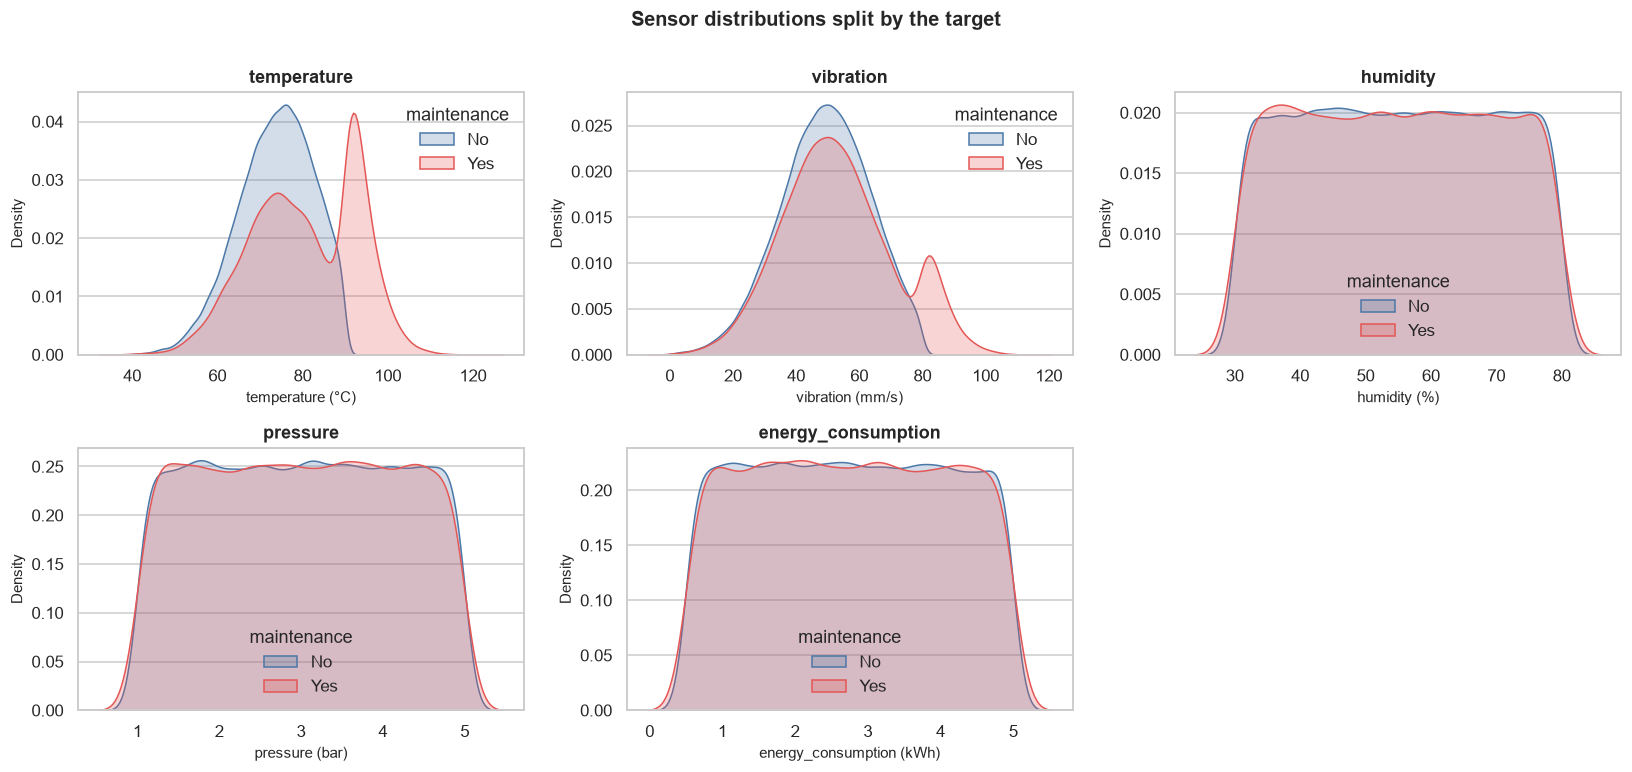

,mean (No),mean (Yes),difference,Cohen's d,Mann-Whitney p
sensor,,,,,
temperature,73.627122,80.753053,7.125931,0.662033,0
vibration,49.176591,53.437112,4.260521,0.265864,5.6e-144
humidity,55.022679,54.884195,-0.138484,-0.009577,0.23
pressure,3.001515,2.995879,-0.005636,-0.004891,0.54
energy_consumption,2.746174,2.750692,0.004517,0.003480,0.66


In [13]:
# Overlay each sensor's distribution for "No" (blue) and "Yes" (red).
# common_norm=False scales each curve on its own, so the shapes compare fairly despite the 80/20 split.
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), SENSORS):
    for k, colour in TARGET_COLORS.items():
        sns.kdeplot(an.loc[an[TARGET] == k, c].dropna(), ax=ax, color=colour, fill=True, alpha=0.25,
                    label="Yes" if k else "No", common_norm=False)
    ax.set(title=c, xlabel=f"{c} ({units[c]})"); ax.legend(title="maintenance")
axes.ravel()[-1].axis("off")
plt.suptitle("Sensor distributions split by the target", y=1.0, fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

# Put numbers on the gaps: difference in means, Cohen's d, and a Mann-Whitney test
rows = []
for c in SENSORS:
    yes = an.loc[an[TARGET] == 1, c].dropna()
    no = an.loc[an[TARGET] == 0, c].dropna()
    pooled_std = np.sqrt((yes.var() + no.var()) / 2)
    rows.append({"sensor": c, "mean (No)": no.mean(), "mean (Yes)": yes.mean(),
                 "difference": yes.mean() - no.mean(),
                 "Cohen's d": (yes.mean() - no.mean()) / pooled_std,
                 "Mann-Whitney p": stats.mannwhitneyu(yes, no).pvalue})
comparison = pd.DataFrame(rows).set_index("sensor")
display(comparison.style.format("{:.3f}").format({"Mann-Whitney p": "{:.2g}"}))

**What we found.**
- **`temperature`**: 80.8 °C on average when maintenance is required vs 73.6 °C when it is not. Cohen's d is about **0.66**, a medium-to-large effect, and by far the biggest gap.
- **`vibration`**: about 53.4 vs 49.2 mm/s (using the absolute value), Cohen's d about **0.27**, a small effect.
- **`humidity`, `pressure`, `energy_consumption`**: the two curves lie on top of each other, the means differ by almost nothing, and Cohen's d is about 0.

**How to read it.** The p-value for temperature and vibration is essentially zero, but so is the p-value of almost any real difference when you have 100,000 rows. A tiny p-value only says "the gap is not zero". It does not say the gap is *useful*. That is why we put the weight on Cohen's d, which tells us how big the gap is. For the three uniform sensors the p-values (about 0.2 to 0.7) agree with d: there is no difference.

**What it means for us.** Temperature and vibration are the only raw sensors that separate the classes, with temperature clearly the stronger. But a gap in the *averages* does not tell us *how* the risk changes. For that, we look at the shape of the relationship in the next step.

## Step 7. Is there a threshold where the risk jumps?

**Purpose.** Step 6 said hotter and more vibrating machines need maintenance more often. A natural question is whether the risk climbs gradually, or whether something happens at a particular level. The answer changes how we should build features and which models suit the data.

**What we did.** Group each sensor into bins and calculate the maintenance rate in every bin, then draw it as a curve. We also plot temperature against vibration for a sample of readings, coloured by the target.

In [14]:
def rate_by_bins(col, bins):
    """Maintenance rate and number of rows inside each bin of a sensor."""
    grouped = an.groupby(pd.cut(an[col], bins), observed=True)[TARGET]
    return grouped.agg(**{"maintenance rate": "mean", "count": "count"}).round(3)

print("Temperature (°C)");     display(rate_by_bins("temperature", [0, 70, 80, 85, 90, 95, 200]))
print("|Vibration| (mm/s)");   display(rate_by_bins("vibration", [-1, 20, 40, 60, 70, 80, 200]))

Temperature (°C)


,maintenance rate,count
temperature,,
"(0, 70]",0.140,26543
"(70, 80]",0.138,32796
"(80, 85]",0.139,12905
"(85, 90]",0.143,7924
"(90, 95]",1.000,3857
"(95, 200]",1.000,1975


|Vibration| (mm/s)


,maintenance rate,count
vibration,,
"(-1, 20]",0.172,2259
"(20, 40]",0.178,22809
"(40, 60]",0.178,49741
"(60, 70]",0.178,16026
"(70, 80]",0.180,6881
"(80, 200]",1.000,2284


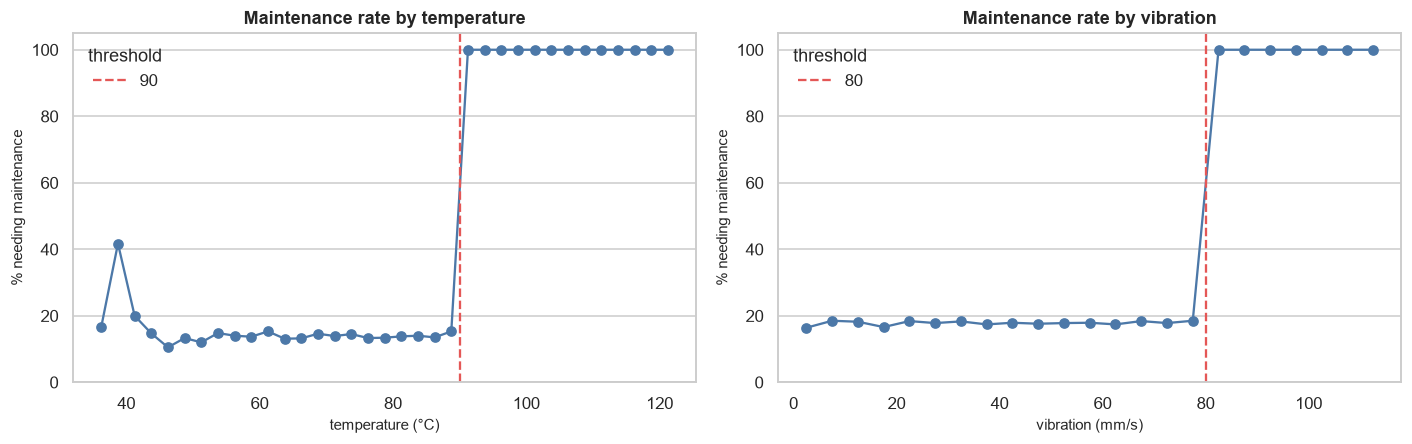

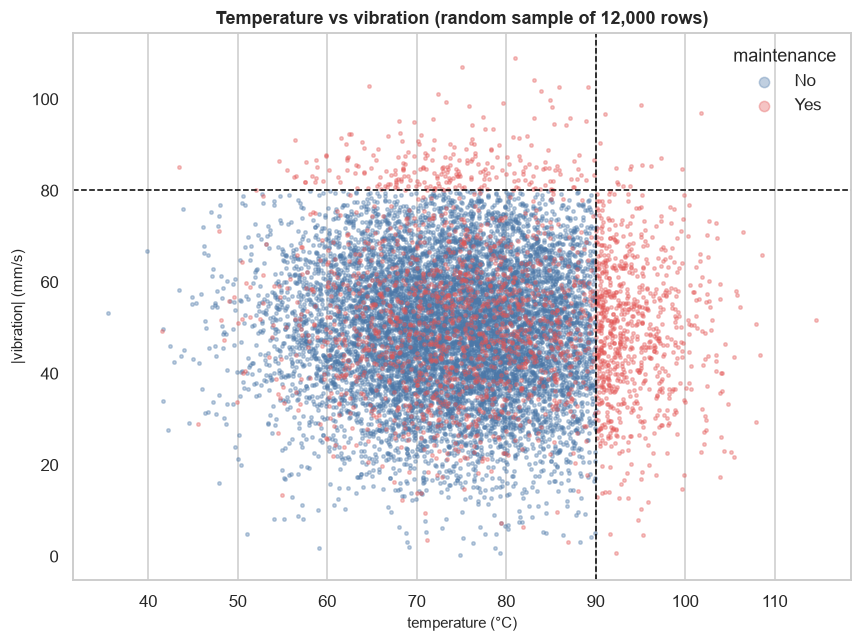

Rows where the rule fires: 7989
   of those, maintenance required: 100.0%
Maintenance rate when it does not fire: 12.7%
Share of ALL maintenance rows the rule catches: 40.6%


In [15]:
# Maintenance rate against each sensor, with the suspected cut-off marked by a red dashed line
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, (c, bins, cutoff) in zip(axes, [("temperature", np.arange(35, 125, 2.5), 90),
                                        ("vibration", np.arange(0, 120, 5), 80)]):
    rate = rate_by_bins(c, bins)["maintenance rate"] * 100
    ax.plot([b.mid for b in rate.index], rate.values, marker="o", color=BLUE)
    ax.axvline(cutoff, color=RED, ls="--", label=str(cutoff))
    ax.set(title=f"Maintenance rate by {c}", xlabel=f"{c} ({units[c]})",
           ylabel="% needing maintenance", ylim=(0, 105))
    ax.legend(title="threshold")
plt.tight_layout(); plt.show()

# Temperature vs vibration on a random sample (12,000 points keeps the chart readable)
sample = an.dropna(subset=["temperature"]).sample(12000, random_state=1)
fig, ax = plt.subplots(figsize=(8, 6))
for k, colour in TARGET_COLORS.items():
    s = sample[sample[TARGET] == k]
    ax.scatter(s.temperature, s.vibration, s=5, alpha=0.35, color=colour, label="Yes" if k else "No")
ax.axvline(90, color="black", ls="--", lw=1); ax.axhline(80, color="black", ls="--", lw=1)
ax.grid(axis="both")
ax.set(xlabel="temperature (°C)", ylabel="|vibration| (mm/s)",
       title="Temperature vs vibration (random sample of 12,000 rows)")
ax.legend(title="maintenance", markerscale=3)
plt.tight_layout(); plt.show()

# How good is the simple rule "temperature > 90 OR |vibration| > 80"?
rule = (an.temperature > 90) | (an.vibration > 80)
needs_maintenance = an[TARGET] == 1
print(f"Rows where the rule fires: {rule.sum()}")
print(f"   of those, maintenance required: {an.loc[rule, TARGET].mean() * 100:.1f}%")
print(f"Maintenance rate when it does not fire: {an.loc[~rule, TARGET].mean() * 100:.1f}%")
print(f"Share of ALL maintenance rows the rule catches: {rule[needs_maintenance].mean() * 100:.1f}%")

**What we found.** This is the most important pattern in the whole analysis.
- Below 90 °C the maintenance rate is flat at about 14%, whether the machine is at 60 °C or 88 °C. At **90 °C and above it jumps straight to 100%**.
- Vibration does the same thing: flat at about 17 to 18% up to 80 mm/s, then **100% above 80 mm/s**.
- The scatter plot shows the same thing in two dimensions. The red points fill everything to the right of the vertical line and above the horizontal line, and below both lines red and blue are mixed together.
- A simple rule, "temperature above 90 or vibration above 80", is right every time it fires, but it only catches about **41% of all the maintenance rows**. The other roughly 59% happen with perfectly normal-looking temperature and vibration.

**How to read it.** The gentle difference in averages we saw in Step 6 was not a smooth trend. It was produced by a hard cut-off, with the high tail of temperature and vibration all landing in the "Yes" group. Under the cut-off, temperature and vibration barely matter. That is also why a correlation coefficient understates their importance (Step 9).

**What it means for us.**
- Models that can learn cut-offs (decision trees, random forests, gradient boosting) are a natural fit. Logistic regression will need explicit threshold features such as `temp_over_90` and `vib_over_80`.
- It also sets an honest expectation: **the sensors alone can only explain part of the target**. Something else is causing maintenance in the other ~59% of cases. We look for it in the next step.

## Step 8. Derived columns and data leakage

**Purpose.** The brief tells us that five columns (`failure_type`, `machine_status`, `anomaly_flag`, `predicted_remaining_life`, `downtime_risk`) are *derived data* rather than sensor readings: they are worked out or assigned by some other process, not measured by the machine. That raises the most important question in this analysis: is it legitimate to use them to predict `maintenance_required`? A column that restates the answer, or that only exists once a machine has already failed, would make a model look brilliant and be useless as an alert system.

**What we did.** Check the maintenance rate for each value of these columns, then look at the rows where *none* of the obvious triggers is present to see what is left.

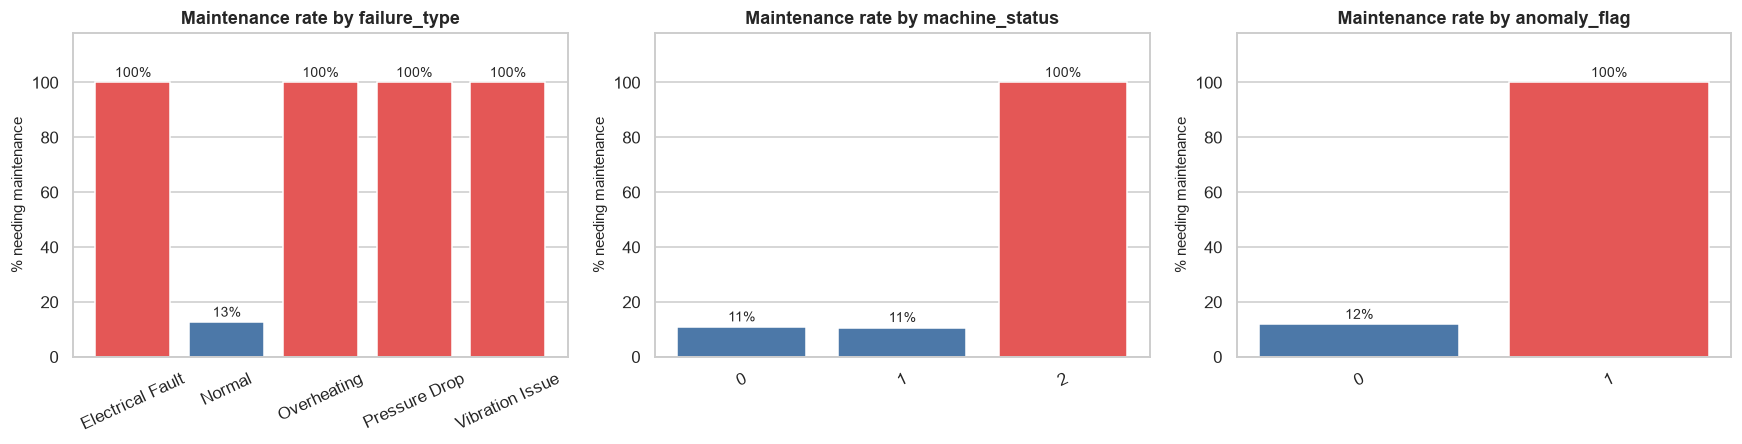

                   mean  count
failure_type                  
Electrical Fault  1.000   1014
Normal            0.126  91899
Overheating       1.000   1989
Pressure Drop     1.000   1969
Vibration Issue   1.000   3129 

                 mean  count
machine_status              
0               0.109   9852
1               0.107  80091
2               1.000  10057 

               mean  count
anomaly_flag              
0             0.118  91084
1             1.000   8916 



In [16]:
# Maintenance rate for each value of the three derived columns (red = always 100%)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, c in zip(axes, ["failure_type", "machine_status", "anomaly_flag"]):
    rate = df.groupby(c)[TARGET].mean() * 100
    ax.bar(rate.index.astype(str), rate, color=[RED if r > 99 else BLUE for r in rate])
    label_bars(ax, rate)
    ax.set(title=f"Maintenance rate by {c}", ylabel="% needing maintenance", ylim=(0, 118))
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

# The same numbers as tables, with row counts
for c in ["failure_type", "machine_status", "anomaly_flag"]:
    print(df.groupby(c)[TARGET].agg(["mean", "count"]).round(3), "\n")

**What we found.**
- Any `failure_type` other than "Normal" (Electrical Fault, Overheating, Pressure Drop, Vibration Issue): **100%** maintenance.
- `machine_status = 2` (failure): **100%** maintenance. Idle (0) and running (1) machines are both at about 11%, so whether a machine is running or idle makes no difference to its risk.
- `anomaly_flag = 1`: **100%** maintenance.

Each of these is a perfect trigger. We now check what is left once those are set aside.

Rows with Normal failure type, not failed, no anomaly: 81,951  ->  maintenance rate 0.020

Predicted remaining life (hours) in those rows, by target:


,count,mean,std,min,25%,50%,75%,max
maintenance_required,,,,,,,,
0,80303.0,259.8,138.5,20.0,140.0,259.0,379.0,499.0
1,1648.0,14.4,2.9,10.0,12.0,14.0,17.0,19.0


,mean,count
predicted_remaining_life,,
"(0, 20]",0.972,5689
"(20, 50]",0.537,10829
"(50, 100]",0.100,9196
"(100, 200]",0.100,18681
"(200, 500]",0.100,55605


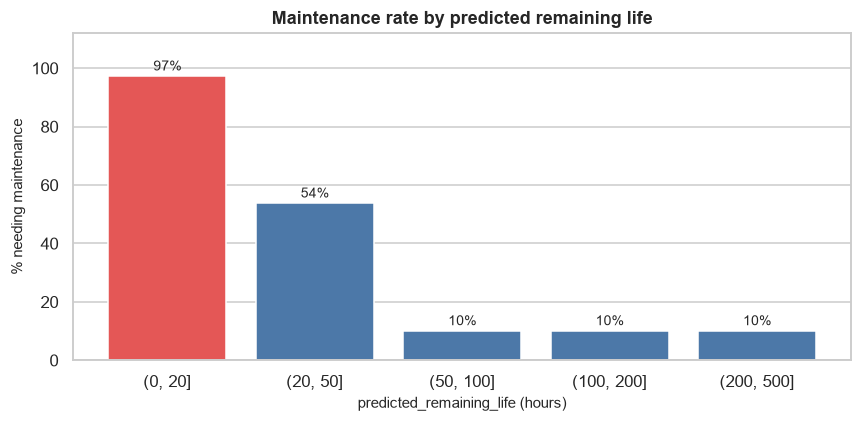

downtime_risk           0.0  0.9   1.0     All
maintenance_required                          
0                     80303    0     0   80303
1                     10781    4  8912   19697
All                   91084    4  8912  100000


In [17]:
# Set aside the rows with an obvious trigger (a failure type, failed status, or anomaly flag).
# What is left is the "ordinary-looking" rows: do any of them still need maintenance?
no_trigger = df[(df.failure_type == "Normal") & (df.machine_status != 2) & (df.anomaly_flag == 0)]
print(f"Rows with Normal failure type, not failed, no anomaly: {len(no_trigger):,}  ->  maintenance rate {no_trigger[TARGET].mean():.3f}")
print("\nPredicted remaining life (hours) in those rows, by target:")
display(no_trigger.groupby(TARGET).predicted_remaining_life.describe().round(1))

# Maintenance rate across all rows, by remaining-life band
life_bins = [0, 20, 50, 100, 200, 500]
life = df.groupby(pd.cut(df.predicted_remaining_life, life_bins), observed=True)[TARGET].agg(["mean", "count"]).round(3)
display(life)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar([str(band) for band in life.index], life["mean"] * 100, color=[RED if r > 0.9 else BLUE for r in life["mean"]])
label_bars(ax, life["mean"] * 100)
ax.set(xlabel="predicted_remaining_life (hours)", ylabel="% needing maintenance", ylim=(0, 112),
       title="Maintenance rate by predicted remaining life")
plt.tight_layout(); plt.show()

# How downtime_risk lines up with the target
print(pd.crosstab(df[TARGET], df.downtime_risk.round(1), margins=True))

**What we found.**
- After removing the obvious triggers, only about **2%** of the remaining rows still need maintenance (1,648 of 81,951). Those rows all have **`predicted_remaining_life` of 19 hours or less**, while rows that do not need maintenance never go below 20.
- Across all rows, remaining life below 20 hours means 97% maintenance. From 20 to 50 hours it is about 54%, and above 50 hours it settles at about 10%, which is the rate left over from the triggers above.
- `downtime_risk` is 0 for every row that does not need maintenance. When maintenance is required it is 1 in about 8,900 of the 19,697 rows (and 0 in the rest). So a value of 1 always means maintenance, but a value of 0 does not rule it out.

**How to read it.** Put together, this looks like a rule: maintenance is required when *any* of these happens: a failure type is recorded, the machine has failed, an anomaly is flagged, the remaining life drops below 20 hours, temperature goes above 90 °C, or vibration goes above 80 mm/s. The first four are the columns we are looking at here.

### The leakage problem
This is where we have to be careful. Several of these derived columns are built around the target itself. `predicted_remaining_life` is defined as the hours left before maintenance is required, `machine_status = 2` means the machine has already failed, and `anomaly_flag` and `failure_type` only say something once a problem has already shown up. If we feed them to a model it will score close to perfect, but it would be useless as an alert system, because the alert is needed *before* those values exist. That is called **data leakage**.

`predicted_remaining_life` is the most tempting one, because remaining-life estimates are a normal tool in predictive maintenance. But here it is defined relative to the maintenance point itself, and below 20 hours it lines up almost exactly with the target, so using it would be reading the answer off the label. The brief does not say exactly when each column is produced, so the final call is our judgement, but the evidence (the perfect triggers above, and the model results in Step 11) strongly supports it.

**What it means for us.**
- The main models will be built on **the raw sensor readings and features engineered from them**.
- The five derived columns will be **excluded** from the models. We keep them only for analysis and as a clearly labelled "what leakage looks like" comparison in Step 11.
- It also explains Step 7: the part of maintenance the sensors cannot see is mostly driven by these derived columns, especially remaining life.

## Step 9. Correlations

**Purpose.** See at a glance how all the numeric variables relate to each other and to the target. We want to confirm two things: that the sensors are not duplicating one another (multicollinearity), and which ones lean toward the target.

**What we did.** Draw a correlation heatmap (lower triangle only, so each pair appears once), using the cleaned analysis frame.

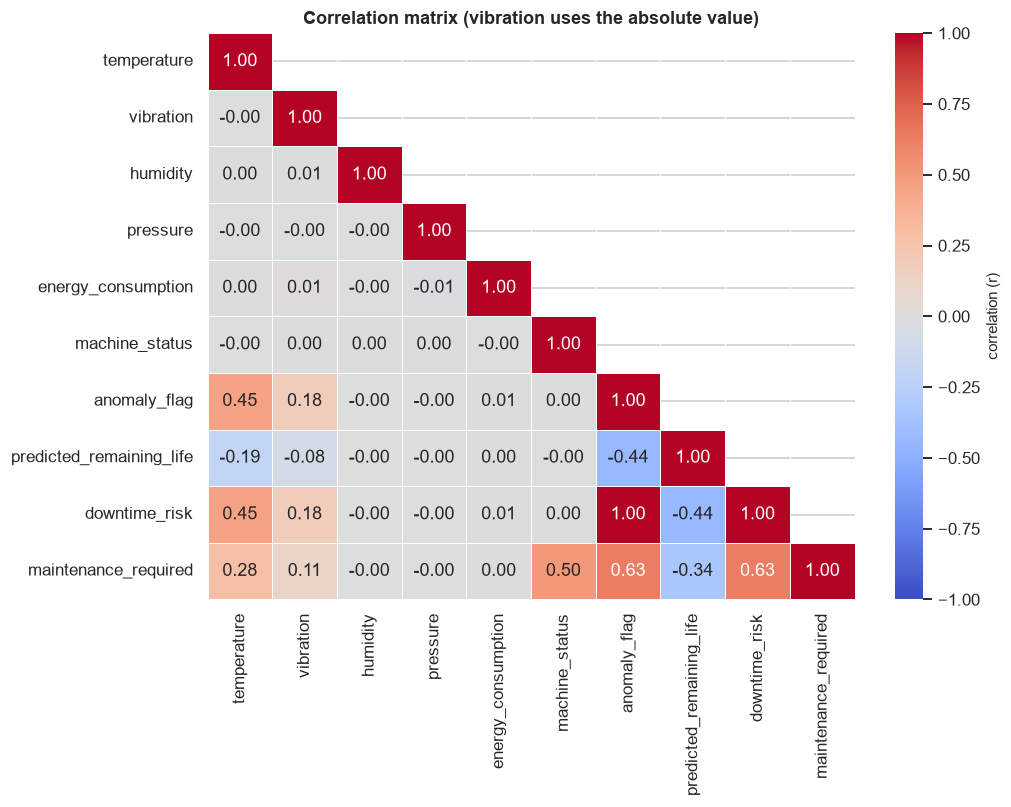

Correlation with the target, strongest first:
anomaly_flag                0.63
downtime_risk               0.63
machine_status              0.50
predicted_remaining_life   -0.34
temperature                 0.28
vibration                   0.11
humidity                   -0.00
pressure                   -0.00
energy_consumption          0.00


In [18]:
# Correlation of every numeric column with every other (vibration is the absolute value)
cols = SENSORS + ["machine_status", "anomaly_flag", "predicted_remaining_life", "downtime_risk", TARGET]
corr = an[cols].corr()

# Show only the lower triangle so each pair appears once
upper_triangle = np.triu(np.ones_like(corr, dtype=bool), k=1)
plt.figure(figsize=(9.5, 7.5))
sns.heatmap(corr, mask=upper_triangle, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"label": "correlation (r)"})
plt.title("Correlation matrix (vibration uses the absolute value)")
plt.tight_layout(); plt.show()

# Just the target column, strongest first
print("Correlation with the target, strongest first:")
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(2).to_string())

**What we found.**
- **Between the sensors the correlations are all about 0.00**, so each sensor carries its own information and there is no multicollinearity to worry about.
- **With the target**, `temperature` is the strongest raw sensor (about 0.28), `vibration` is smaller (about 0.1), and humidity, pressure and energy are 0.
- The derived columns correlate much more strongly: `anomaly_flag` and `downtime_risk` about 0.63, `machine_status` 0.50, `predicted_remaining_life` -0.34 (less remaining life, more maintenance).

**How to read it.** A correlation of 0.28 sounds weak, but this is a case where correlation is misleading. In Step 7 we saw that temperature has a *perfect* effect above 90 °C and *no* effect below it. Correlation only measures straight-line relationships, so it averages those two behaviours into one modest number.

**What it means for us.**
- We should not discard a feature just because its correlation looks low.
- The high correlations of the derived columns are one more sign of leakage (Step 8).
- Because the pattern is a cut-off rather than a straight line, tree-based models are a good first choice.

## Step 10. Machine and time effects

**Purpose.** Check whether some machines are more failure-prone than others, or whether the maintenance rate drifts over time. If so, `machine_id` or time-based features could be useful. If not, we can safely ignore them.

**What we did.** Plot the maintenance rate per machine and per day. As in Step 2.2, we shade the range that pure chance could explain, so we are not tempted to read meaning into random wobble.

Maintenance rate per machine: min 0.173, max 0.215, std 0.009
Chance band per machine (±2 SE): 0.179 to 0.215 -> machines outside: 3 of 50
Daily maintenance rate: min 0.168, max 0.222


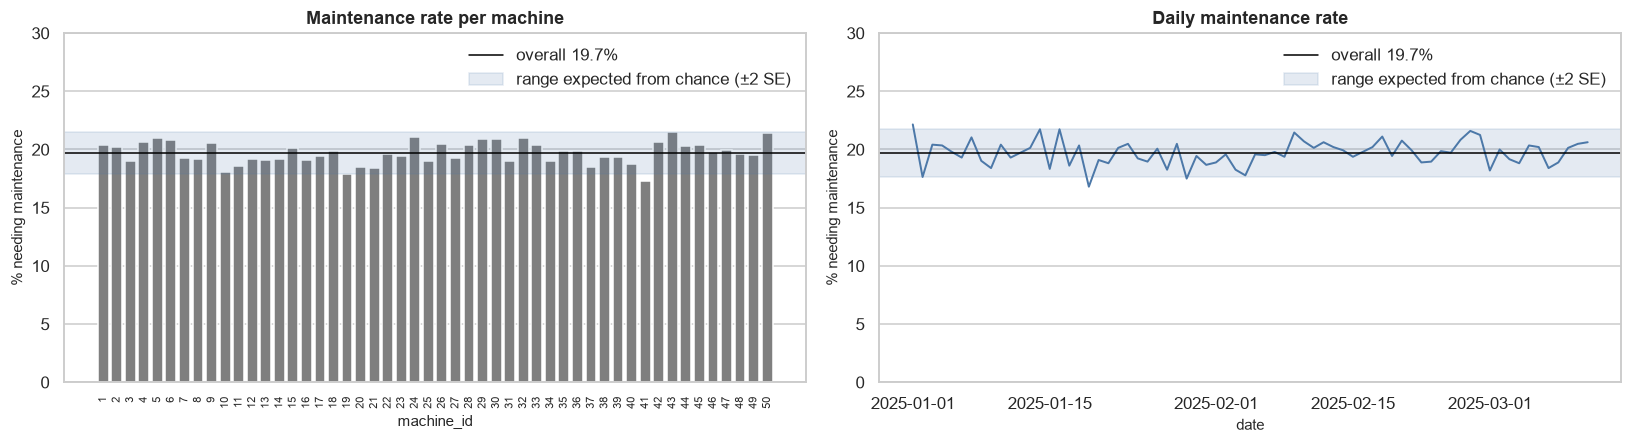

In [19]:
overall = df[TARGET].mean()
rate_by_machine = df.groupby("machine_id")[TARGET].mean()
rate_by_day = df.set_index("timestamp")[TARGET].resample("D").mean()

# Each machine has about 2,000 readings and each day has 1,440 (one per minute).
# That decides how far a rate can wobble by luck alone.
n_machine = len(df) / df.machine_id.nunique()
n_day = 1440
m_low, m_high = chance_band(overall, n_machine)
n_outside = int(((rate_by_machine < m_low) | (rate_by_machine > m_high)).sum())

print(f"Maintenance rate per machine: min {rate_by_machine.min():.3f}, max {rate_by_machine.max():.3f}, std {rate_by_machine.std():.3f}")
print(f"Chance band per machine (±2 SE): {m_low:.3f} to {m_high:.3f} -> machines outside: {n_outside} of 50")
print(f"Daily maintenance rate: min {rate_by_day.min():.3f}, max {rate_by_day.max():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))

# Left: rate for each machine
ax[0].bar(rate_by_machine.index.astype(str), rate_by_machine * 100, color=GREY)
shade_chance_band(ax[0], overall, n_machine)
ax[0].set(ylim=(0, 30), xlabel="machine_id", ylabel="% needing maintenance", title="Maintenance rate per machine")
ax[0].tick_params(axis="x", labelrotation=90, labelsize=7)

# Right: rate for each day
ax[1].plot(rate_by_day.index, rate_by_day * 100, color=BLUE, lw=1.3)
shade_chance_band(ax[1], overall, n_day)
ax[1].set(ylim=(0, 30), xlabel="date", ylabel="% needing maintenance", title="Daily maintenance rate")
plt.tight_layout(); plt.show()

**What we found.** Maintenance rates across the 50 machines run from about 17% to 21.5%, and the daily rate stays within a narrow band for the whole 10 weeks with no upward or downward trend.

**How to read it.** The shaded band is how far a machine or a day would wander from 19.7% purely by chance. Nearly all the bars and days sit inside it, and the few that step outside are what we would expect to see when we test 50 machines and about 70 days. So the differences look like noise, not real machine personalities or trends.

**What it means for us.**
- `machine_id` is a label, not a quantity, so it should never be passed to a model as a plain number. It does not look useful as a feature either.
- We saw no time trend, so we do not expect time-of-day or date features to help much. Because the machines are interleaved in time, per-machine rolling averages are possible, and we will test whether they add anything in Week 7. We are not assuming they will.

## Step 11. Quick baseline model: which features matter?

**Purpose.** All of the earlier steps are about describing the data. Here we do a fast check of how well the raw sensors can actually *predict* maintenance, and use it to test two claims we have made: that threshold features are worth adding, and that the derived columns leak the answer. It also gives us a first answer to the brief's question about which features contribute most.

**What we did.** Train the same Random Forest three times on an 80/20 stratified split: (1) the five cleaned sensors only, (2) the sensors plus two threshold flags, and (3) the sensors plus the derived columns. We compare ROC-AUC, PR-AUC and recall. For the sensors-only model we also measure feature importance in two ways: the built-in importance of the forest, and *permutation importance* (shuffle one feature on unseen data and see how much the score drops).

*This is deliberately a quick check, not our final model. The imputation medians use all the data (see Step 3), and we have done no tuning.*

,ROC-AUC,PR-AUC,Recall (Yes)
1. Sensors only,0.708,0.596,0.4
2. Sensors + threshold flags,0.707,0.599,0.4
3. Sensors + derived columns (leaky),1.000,1.000,1.0


,built-in importance (share),permutation importance (drop in ROC-AUC)
temperature,0.492,0.157
vibration,0.252,0.053
humidity,0.093,-0.004
pressure,0.082,-0.004
energy_consumption,0.082,-0.002


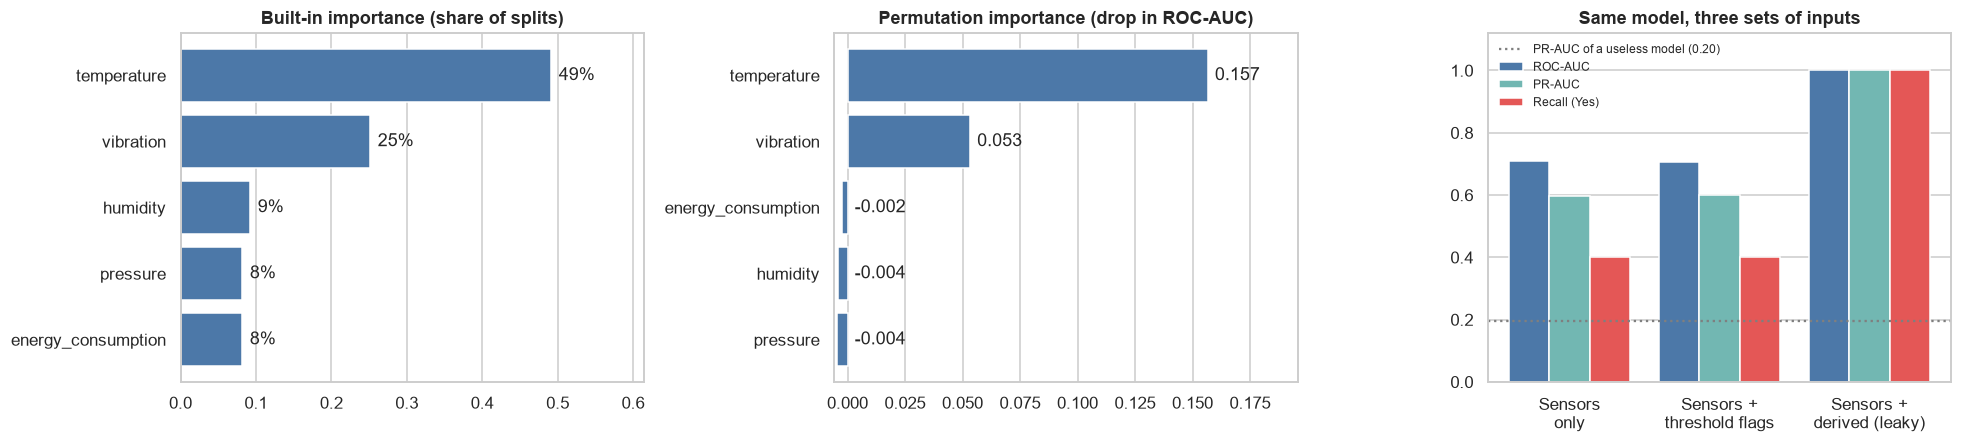

In [20]:
d = df_clean.copy()

# Two threshold flags from Step 7, and the list of derived (leaky) columns from Step 8
d["temp_over_90"] = (d.temperature > 90).astype(int)
d["vib_over_80"] = (d.vibration > 80).astype(int)
derived = ["machine_status", "anomaly_flag", "predicted_remaining_life", "downtime_risk"]
y = d[TARGET]

def fit_eval(cols):
    """Train a Random Forest on `cols` and score it on a held-out 20% (stratified, so it keeps the 80/20 balance)."""
    X_train, X_test, y_train, y_test = train_test_split(d[cols], y, test_size=0.2, random_state=42, stratify=y)
    model = RandomForestClassifier(n_estimators=150, min_samples_leaf=5, n_jobs=-1, random_state=42).fit(X_train, y_train)
    prob = model.predict_proba(X_test)[:, 1]                 # the model's chance that the answer is "Yes"
    scores = {"ROC-AUC": roc_auc_score(y_test, prob),
              "PR-AUC": average_precision_score(y_test, prob),
              "Recall (Yes)": recall_score(y_test, prob >= 0.5)}
    return model, scores, X_test, y_test

# Same model, three different sets of inputs
inputs = {"1. Sensors only": SENSORS,
          "2. Sensors + threshold flags": SENSORS + ["temp_over_90", "vib_over_80"],
          "3. Sensors + derived columns (leaky)": SENSORS + derived}
fitted = {name: fit_eval(cols) for name, cols in inputs.items()}
results = pd.DataFrame({name: f[1] for name, f in fitted.items()}).T
display(results.round(3))

# Which sensors matter? Two views of the sensors-only model:
#  - built-in importance: how much each feature was used to split the trees (can credit noise features)
#  - permutation importance: how much the held-out ROC-AUC DROPS when one feature is shuffled (the fairer test)
model, _, X_test, y_test = fitted["1. Sensors only"]
built_in = pd.Series(model.feature_importances_, index=SENSORS)
perm = permutation_importance(model, X_test, y_test, scoring="roc_auc", n_repeats=5, random_state=42)
permuted = pd.Series(perm.importances_mean, index=SENSORS)
display(pd.DataFrame({"built-in importance (share)": built_in, "permutation importance (drop in ROC-AUC)": permuted}).round(3))

fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))

# Panel 1 and 2: the two importance views
for a, values, title, fmt in [(ax[0], built_in, "Built-in importance (share of splits)", "{:.0%}"),
                              (ax[1], permuted, "Permutation importance (drop in ROC-AUC)", "{:.3f}")]:
    values = values.sort_values()
    a.barh(values.index, values, color=BLUE)
    for i, v in enumerate(values):
        a.text(max(v, 0) + values.max() * 0.02, i, fmt.format(v), va="center")
    a.set(title=title, xlim=(min(0, values.min() * 1.3), values.max() * 1.25))
    a.grid(axis="x"); a.grid(axis="y", visible=False)

# Panel 3: the three scores for each set of inputs
x, width = np.arange(3), 0.27
for i, (metric, colour) in enumerate(zip(["ROC-AUC", "PR-AUC", "Recall (Yes)"], [BLUE, "#72B7B2", RED])):
    ax[2].bar(x + (i - 1) * width, results[metric], width, label=metric, color=colour)
ax[2].axhline(y.mean(), color=GREY, ls=":", label=f"PR-AUC of a useless model ({y.mean():.2f})")
ax[2].set_xticks(x)
ax[2].set_xticklabels(["Sensors\nonly", "Sensors +\nthreshold flags", "Sensors +\nderived (leaky)"])
ax[2].set(ylim=(0, 1.12), title="Same model, three sets of inputs")
ax[2].legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

**What we found.**
- **Sensors only:** ROC-AUC of about **0.71**, PR-AUC about 0.60 (against about 0.20 for a useless model) and recall of about **0.40**.
- **Which sensors matter.** The built-in importance gives temperature 49%, vibration 25% and about 8 to 9% each to humidity, pressure and energy. Permutation importance tells a sharper story: shuffling `temperature` costs about **0.157** ROC-AUC and shuffling `vibration` about **0.053**, while shuffling humidity, pressure or energy costs essentially nothing (values around zero, even slightly negative).
- **Adding threshold flags:** essentially no change. Our Step 7 guess that these features "should help a lot" was too optimistic for this model. The Random Forest has already found the 90 °C and 80 mm/s cut-offs by itself. The flags are still worth keeping for Logistic Regression, which cannot discover cut-offs on its own.
- **Adding the derived columns:** everything jumps to **1.0**, which is the leakage we described in Step 8.

**How to read it.** Built-in importance has to share out 100% among the features, so it hands the three uniform sensors a few percent each simply because the trees kept splitting on them while fitting noise. Permutation importance asks a harder question on data the model has not seen: "does the model get worse without this feature?" A value near zero means the feature adds nothing, and a slightly negative one just means shuffling it changed the score by chance. This agrees with Steps 5 and 6, where those three sensors were flat and identical across the two classes.

Also notice that the sensors-only recall of about 0.40 is almost exactly the 41% of maintenance rows that our simple two-threshold rule caught in Step 7. The model is not finding anything much cleverer than that rule, and the cap on performance comes from the data, not from the model. The remaining cases are triggered by information the raw sensors do not contain.

**What it means for us.**
- **Temperature and vibration are the key features** for the brief's feature question, with temperature clearly the more important. Humidity, pressure and energy consumption contribute nothing we can measure.
- The real modelling challenge is **getting good recall from the raw sensors**, and a better algorithm alone is unlikely to close the gap. The gains are more likely to come from features that capture a machine's recent history (for example rolling averages or trends per machine), from handling the class imbalance, and from choosing the decision threshold carefully rather than using 0.5.

## Step 12. Summary and plan

**Purpose.** Pull everything together: what we learned, what we will do about it, and what we are still unsure about.

### Key insights and the action each one leads to

| # | What we learned | What we will do |
|---|---|---|
| 1 | `temperature` has 14% missing values, and the gaps look random (Step 2.2) | Fill with the per-machine median (computed on the training split only) and add a `temperature_missing` flag. Already demonstrated in Step 3. |
| 2 | 6.7% of `vibration` values are negative, but they mirror the positive values and the sign has no link to the target (2.4) | Use `abs(vibration)` and keep a `vibration_was_negative` flag. |
| 3 | The high extremes of temperature and vibration are all "maintenance required" (2.5) | Keep the outliers. They are real events, not errors. |
| 4 | Only about 20% of rows are "Yes" (Step 4) | Stratified splits, class weights, and judge by recall, F1 and PR-AUC, not accuracy. |
| 5 | Temperature above 90 °C or vibration above 80 mm/s always means maintenance, but this only covers about 41% of cases (Step 7) | Add threshold features for linear models and use tree-based models. Expect the raw sensors to have a performance ceiling (about 0.71 ROC-AUC, about 0.40 recall at default settings). |
| 6 | Humidity, pressure and energy are uniform, show no link to the target, and have about zero permutation importance. Temperature (0.157 AUC drop) and vibration (0.053) are the key features (Steps 5, 6, 11) | Report temperature and vibration as the main drivers. Test dropping the other three, and keep them only if they help in cross-validation. |
| 7 | `failure_type`, `machine_status`, `anomaly_flag`, `predicted_remaining_life` and `downtime_risk` leak the answer (Step 8, 11) | Exclude them from the models and document why. |
| 8 | Machines and days behave alike, and `machine_id` is a label (Step 10) | Do not feed `machine_id` in as a number. Test per-machine rolling features as an experiment. |

### Plan for Week 7
- Build at least three models: **Logistic Regression** (a simple, interpretable baseline), **Random Forest**, and **Gradient Boosting** (XGBoost or LightGBM).
- Put cleaning, imputation and scaling inside a pipeline so that they are fitted on training data only.
- Tune with cross-validation and compare on recall, F1 and PR-AUC, and choose the decision threshold on purpose.
- Report feature importance from the final models (permutation importance, as in Step 11) to answer which features contribute most.

### Why these three models
The brief asks us to justify our models using the dataset. These choices follow from what we found:

| Model | Why it suits this data |
|---|---|
| Logistic Regression | Simple, fast and easy to explain to a maintenance team, so it is a fair baseline. It can only draw straight-line boundaries, so it needs the threshold flags (`temp_over_90`, `vib_over_80`) to capture the cut-offs from Step 7, and the sensors should be scaled. |
| Random Forest | Learns cut-offs and interactions by itself, needs no scaling, copes with the 80/20 imbalance through class weights, and is hard to overfit. Its importances also help answer the brief's feature question. |
| Gradient Boosting (XGBoost or LightGBM) | Also learns cut-offs, and usually gets the most out of tabular data by correcting its own mistakes step by step. It is worth testing whether it can do better than the forest on the roughly 59% of cases that sit below the cut-offs. It needs careful tuning to avoid overfitting. |

Together they cover a linear model, a bagged ensemble and a boosted ensemble, so the comparison tells us whether the cut-off structure we found really needs a non-linear model.

### What we are still unsure about
- The brief confirms the derived columns are derived, but not exactly when each one is produced. We excluded them because they restate or follow the target. If we learn that one of them (most likely `predicted_remaining_life`) really is available ahead of time in the real alert system, we should revisit that decision and say so in the report.
- The cut-offs at 90 °C and 80 mm/s are so clean that they look like rules written into the data rather than natural machine behaviour. If this reflects how the real alert system works, that is good to know, but we should say so openly in the report.
- Our ~41% coverage figure and the baseline scores come from one split of one dataset, so they should be read as rough guides, not exact values.